In [2]:

# # ====================================================================
# # MLflow Experiment Tracking & Model Registry - Beijing PM2.5
# # ====================================================================

# import re
# import time
# from pathlib import Path
# from datetime import datetime

# import joblib
# import mlflow
# import mlflow.xgboost
# import xgboost as xgb
# import pandas as pd
# import numpy as np
# import matplotlib.pyplot as plt

# from sklearn.metrics import (
#     mean_absolute_error,
#     mean_squared_error,
#     r2_score
# )

# from mlflow.models import infer_signature


# # ====================================================================
# # إعداد MLflow
# # ====================================================================

# mlflow.set_tracking_uri("http://localhost:5000")

# EXPERIMENT_NAME = "PM25_Prediction_Experiments"
# REGISTERED_MODEL_NAME = "PM25_XGBoost_Regression_Predictor"

# mlflow.set_experiment(EXPERIMENT_NAME)

# # إنشاء مجلد حفظ الملفات
# OUTPUT_DIR = Path("models")
# OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# print("MLflow Version:", mlflow.__version__)
# print("XGBoost Version:", xgb.__version__)
# print("Tracking URI:", mlflow.get_tracking_uri())


# # ====================================================================
# # تحديد رقم التجربة التالي
# # ====================================================================

# def get_next_experiment_version(experiment_name):

#     experiment = mlflow.get_experiment_by_name(experiment_name)

#     if experiment is None:
#         return 1

#     runs = mlflow.search_runs(
#         experiment_ids=[experiment.experiment_id],
#         order_by=["attributes.start_time DESC"]
#     )

#     if runs.empty:
#         return 1

#     versions = []

#     for run_name in runs.get(
#         "tags.mlflow.runName",
#         pd.Series(dtype=str)
#     ).dropna():

#         match = re.search(r"_v(\d+)_", run_name)

#         if match:
#             versions.append(int(match.group(1)))

#     return max(versions, default=0) + 1


# # ====================================================================
# # تحميل البيانات وأدوات تجهيزها
# # ====================================================================

# train_csv = Path("Beijing_PM25_Training_Ready_75896.csv")

# encoder_path = Path("pm25_encoder.pkl")
# features_path = Path("pm25_feature_columns.pkl")

# # التحقق من وجود الملفات
# required_files = [
#     train_csv,
#     encoder_path,
#     features_path
# ]

# for file_path in required_files:

#     if not file_path.exists():
#         raise FileNotFoundError(
#             f"الملف غير موجود: {file_path.resolve()}"
#         )

# # تحميل البيانات
# df = pd.read_csv(train_csv)

# # تحميل أداة ترميز المحطات وأسماء الخصائص
# encoder = joblib.load(encoder_path)
# feature_columns = joblib.load(features_path)

# # التحقق من الأعمدة المطلوبة
# required_columns = [
#     "No",
#     "year",
#     "month",
#     "day",
#     "hour",
#     "PM2.5",
#     "station",
#     "DEWP",
#     "TEMP",
#     "PRES"
# ]

# missing_columns = [
#     col for col in required_columns
#     if col not in df.columns
# ]

# if missing_columns:
#     raise ValueError(
#         f"أعمدة مفقودة في البيانات: {missing_columns}"
#     )

# # التحقق من القيم المفقودة
# if df[required_columns].isnull().any().any():
#     raise ValueError(
#         "توجد قيم مفقودة في البيانات، يرجى معالجتها أولاً."
#     )

# print("\nDataset Information")
# print("Dataset Shape:", df.shape)
# print("Number of Stations:", df["station"].nunique())


# # ====================================================================
# # تجهيز التاريخ وترتيب البيانات زمنياً
# # ====================================================================

# df["Date"] = pd.to_datetime(
#     df[["year", "month", "day", "hour"]]
# )

# df = df.sort_values(
#     by=["station", "Date"]
# ).copy()


# # ====================================================================
# # تقسيم البيانات زمنياً لكل محطة
# # ====================================================================

# train_indices = []
# test_indices = []

# for station_name, station_data in df.groupby("station", sort=False):

#     station_data = station_data.sort_values("Date")

#     split_index = int(len(station_data) * 0.8)

#     train_indices.extend(
#         station_data.index[:split_index]
#     )

#     test_indices.extend(
#         station_data.index[split_index:]
#     )


# # ====================================================================
# # تجهيز الخصائص وترميز محطات الرصد
# # ====================================================================

# base_features = [
#     "year",
#     "month",
#     "day",
#     "hour",
#     "DEWP",
#     "TEMP",
#     "PRES"
# ]

# X_base = df[base_features].copy()

# # تحويل أسماء المحطات إلى أعمدة رقمية
# station_encoded = encoder.transform(
#     df[["station"]]
# )

# # تحويل المصفوفة عند الحاجة
# if hasattr(station_encoded, "toarray"):
#     station_encoded = station_encoded.toarray()

# station_df = pd.DataFrame(
#     station_encoded,
#     columns=encoder.get_feature_names_out(["station"]),
#     index=df.index
# )

# # دمج الخصائص الأساسية مع بيانات المحطات
# X = pd.concat(
#     [X_base, station_df],
#     axis=1
# )

# # مطابقة أسماء وترتيب أعمدة التدريب الأصلية
# X = X.reindex(
#     columns=feature_columns,
#     fill_value=0
# )

# # تحديد المتغير المستهدف
# y = df["PM2.5"]

# # إنشاء بيانات التدريب والاختبار
# X_train = X.loc[train_indices].copy()
# X_test = X.loc[test_indices].copy()

# y_train = y.loc[train_indices].copy()
# y_test = y.loc[test_indices].copy()

# # التحقق من تجهيز البيانات
# if list(X_train.columns) != list(feature_columns):
#     raise ValueError("ترتيب أعمدة التدريب غير مطابق!")

# print("\nData Splitting Results")
# print("Training Rows:", len(X_train))
# print("Testing Rows:", len(X_test))
# print("Number of Features:", X_train.shape[1])


# # ====================================================================
# # إعداد معاملات XGBoost
# # ====================================================================

# xgb_params = {
#     "objective": "reg:squarederror",
#     "n_estimators": 500,
#     "learning_rate": 0.05,
#     "max_depth": 4,
#     "subsample": 0.8,
#     "colsample_bytree": 0.8,
#     "min_child_weight": 5,
#     "reg_alpha": 0.1,
#     "reg_lambda": 1,
#     "eval_metric": "rmse",
#     "random_state": 42,
#     "n_jobs": -1
# }


# # ====================================================================
# # بدء تجربة MLflow
# # ====================================================================

# version = get_next_experiment_version(EXPERIMENT_NAME)

# run_name = (
#     f"{EXPERIMENT_NAME}_v{version}_"
#     f"{datetime.now().strftime('%Y-%m-%d_%H-%M-%S')}"
# )

# start_time = time.time()

# with mlflow.start_run(run_name=run_name) as run:

#     print("\nRun ID:", run.info.run_id)
#     print("Experiment Version:", version)

#     # تسجيل معلومات التجربة
#     mlflow.set_tags({
#         "model_family": "XGBoost",
#         "task": "regression",
#         "dataset": "Beijing PM2.5",
#         "experiment_version": str(version)
#     })

#     # تسجيل معلومات البيانات
#     mlflow.log_params({
#         "dataset_path": str(train_csv.resolve()),
#         "dataset_rows": len(df),
#         "number_of_features": X.shape[1],
#         "training_rows": len(X_train),
#         "testing_rows": len(X_test),
#         "split_method": "Chronological 80/20 per station"
#     })

#     # تسجيل البيانات المستخدمة في التدريب
#     dataset = mlflow.data.from_pandas(
#         df,
#         source=str(train_csv.resolve()),
#         targets="PM2.5"
#     )

#     mlflow.log_input(
#         dataset,
#         context="training"
#     )

#     # تسجيل معاملات النموذج
#     mlflow.log_params(xgb_params)

#     # =================================================================
#     # تدريب النموذج
#     # =================================================================

#     xgb_model = xgb.XGBRegressor(**xgb_params)

#     training_start = time.perf_counter()

#     xgb_model.fit(
#         X_train,
#         y_train
#     )

#     training_time = time.perf_counter() - training_start

#     # =================================================================
#     # التنبؤ وتقييم النموذج
#     # =================================================================

#     prediction_start = time.perf_counter()

#     xgb_pred = xgb_model.predict(X_test)

#     prediction_time = time.perf_counter() - prediction_start

#     mae = mean_absolute_error(
#         y_test,
#         xgb_pred
#     )

#     rmse = np.sqrt(
#         mean_squared_error(y_test, xgb_pred)
#     )

#     r2 = r2_score(
#         y_test,
#         xgb_pred
#     )

#     # =================================================================
#     # تسجيل مقاييس الأداء
#     # =================================================================

#     mlflow.log_metrics({
#         "MAE": float(mae),
#         "RMSE": float(rmse),
#         "R2_Score": float(r2),
#         "training_time_seconds": float(training_time),
#         "prediction_time_seconds": float(prediction_time)
#     })

#     print("\nModel Evaluation")
#     print(f"MAE: {mae:.4f}")
#     print(f"RMSE: {rmse:.4f}")
#     print(f"R2 Score: {r2:.4f}")
#     print(f"Training Time: {training_time:.4f} seconds")
#     print(f"Prediction Time: {prediction_time:.4f} seconds")

#     # =================================================================
#     # حفظ النموذج محلياً
#     # =================================================================

#     pkl_path = OUTPUT_DIR / f"xgb_pm25_model_v{version}.pkl"

#     joblib.dump(
#         xgb_model,
#         pkl_path
#     )

#     # تسجيل ملف النموذج ضمن ملفات التجربة
#     mlflow.log_artifact(
#         str(pkl_path),
#         artifact_path="joblib_model"
#     )

#     model_size_mb = pkl_path.stat().st_size / (1024 ** 2)

#     mlflow.log_metric(
#         "model_size_mb",
#         float(model_size_mb)
#     )

#     # =================================================================
#     # إنشاء Model Signature
#     # =================================================================

#     input_example = X_test.iloc[:5].copy()

#     example_predictions = xgb_model.predict(
#         input_example
#     )

#     signature = infer_signature(
#         input_example,
#         example_predictions
#     )

#     # =================================================================
#     # تسجيل النموذج في MLflow Model Registry
#     # =================================================================

#     model_info = mlflow.xgboost.log_model(
#         xgb_model,
#         name="xgboost-pm25-model",
#         registered_model_name=REGISTERED_MODEL_NAME,
#         input_example=input_example,
#         signature=signature,
#         pip_requirements=[
#             f"mlflow=={mlflow.__version__}",
#             f"xgboost=={xgb.__version__}",
#             f"pandas=={pd.__version__}",
#             f"numpy=={np.__version__}",
#             f"scikit-learn"
#         ]
#     )

#     print("\nLogged Model URI:", model_info.model_uri)
#     print("Logged Model ID:", model_info.model_id)

#     # =================================================================
#     # حفظ أدوات تجهيز البيانات
#     # =================================================================

#     mlflow.log_artifact(
#         str(encoder_path),
#         artifact_path="preprocessing"
#     )

#     mlflow.log_artifact(
#         str(features_path),
#         artifact_path="preprocessing"
#     )

#     # =================================================================
#     # تسجيل أهمية الخصائص
#     # =================================================================

#     feature_importance_df = pd.DataFrame({
#         "Feature": X_train.columns.astype(str),
#         "Importance": xgb_model.feature_importances_
#     }).sort_values(
#         by="Importance",
#         ascending=False
#     )

#     feature_importance_path = (
#         OUTPUT_DIR / f"xgb_pm25_feature_importance_v{version}.png"
#     )

#     plt.figure(figsize=(10, 6))

#     plt.barh(
#         feature_importance_df["Feature"].head(20)[::-1],
#         feature_importance_df["Importance"].head(20)[::-1]
#     )

#     plt.title("XGBoost PM2.5 Feature Importance")
#     plt.xlabel("Importance")
#     plt.ylabel("Feature")
#     plt.tight_layout()

#     plt.savefig(
#         feature_importance_path,
#         dpi=150,
#         bbox_inches="tight"
#     )

#     plt.close()

#     mlflow.log_artifact(
#         str(feature_importance_path),
#         artifact_path="plots"
#     )

#     # =================================================================
#     # رسم مقارنة القيم الحقيقية والمتوقعة
#     # =================================================================

#     comparison_path = (
#         OUTPUT_DIR / f"pm25_actual_vs_predicted_v{version}.png"
#     )

#     plt.figure(figsize=(8, 6))

#     plt.scatter(
#         y_test,
#         xgb_pred,
#         alpha=0.4
#     )

#     plt.plot(
#         [y_test.min(), y_test.max()],
#         [y_test.min(), y_test.max()],
#         linestyle="--"
#     )

#     plt.title("Actual vs Predicted PM2.5")
#     plt.xlabel("Actual PM2.5")
#     plt.ylabel("Predicted PM2.5")
#     plt.tight_layout()

#     plt.savefig(
#         comparison_path,
#         dpi=150,
#         bbox_inches="tight"
#     )

#     plt.close()

#     mlflow.log_artifact(
#         str(comparison_path),
#         artifact_path="plots"
#     )

#     # =================================================================
#     # تحليل الأخطاء المتبقية
#     # =================================================================

#     residuals = y_test.to_numpy() - xgb_pred

#     residual_path = (
#         OUTPUT_DIR / f"pm25_residuals_v{version}.png"
#     )

#     plt.figure(figsize=(8, 6))

#     plt.scatter(
#         xgb_pred,
#         residuals,
#         alpha=0.4
#     )

#     plt.axhline(
#         y=0,
#         linestyle="--"
#     )

#     plt.title("PM2.5 Residual Analysis")
#     plt.xlabel("Predicted PM2.5")
#     plt.ylabel("Residuals")
#     plt.tight_layout()

#     plt.savefig(
#         residual_path,
#         dpi=150,
#         bbox_inches="tight"
#     )

#     plt.close()

#     mlflow.log_artifact(
#         str(residual_path),
#         artifact_path="plots"
#     )

#     # =================================================================
#     # تسجيل تقرير تقييم النموذج
#     # =================================================================

#     report_path = (
#         OUTPUT_DIR / f"pm25_evaluation_report_v{version}.txt"
#     )

#     with open(
#         report_path,
#         "w",
#         encoding="utf-8"
#     ) as file:

#         file.write("PM2.5 XGBoost Model Evaluation\n")
#         file.write("=" * 40 + "\n")

#         file.write(f"MAE: {mae:.4f}\n")
#         file.write(f"RMSE: {rmse:.4f}\n")
#         file.write(f"R2 Score: {r2:.4f}\n")

#         file.write(
#             f"Training Time: {training_time:.4f} seconds\n"
#         )

#         file.write(
#             f"Prediction Time: {prediction_time:.4f} seconds\n"
#         )

#         file.write(
#             f"Model Size: {model_size_mb:.4f} MB\n"
#         )

#     mlflow.log_artifact(
#         str(report_path),
#         artifact_path="evaluation"
#     )

#     # =================================================================
#     # تسجيل مدة التجربة
#     # =================================================================

#     duration = time.time() - start_time

#     mlflow.log_metric(
#         "total_experiment_seconds",
#         float(duration)
#     )

#     print("\nExperiment Completed Successfully!")
#     print("Run ID:", run.info.run_id)
#     print("Registered Model:", REGISTERED_MODEL_NAME)
#     print("Model URI:", model_info.model_uri)
#     print(f"Total Duration: {duration:.2f} seconds")


# print("\nFinished Successfully!")


2026/11/01 01:24:42 INFO mlflow.tracking.fluent: Experiment with name 'PM25_Prediction_Experiments' does not exist. Creating a new experiment.


MLflow Tracking URI: http://127.0.0.1:5001
Experiment Name: PM25_Prediction_Experiments
Registered Model Name: PM25_XGBoost_Regression_Predictor

تم الاتصال بخادم MLflow بنجاح!
عدد التجارب: 3

تم تحميل البيانات بنجاح
Dataset Shape: (75896, 10)
Feature Columns: ['year', 'month', 'day', 'hour', 'DEWP', 'TEMP', 'PRES', 'station_Aotizhongxin', 'station_US_Embassy']

تم تجهيز Features بنجاح
X Shape: (75896, 9)
y Shape: (75896,)

تم تقسيم البيانات بنجاح
X_train: (60716, 9)
X_test: (15180, 9)
y_train: (60716,)
y_test: (15180,)

البيانات سليمة وجاهزة للتدريب

MLflow Run ID: 5a527f944d1340d2ad374ac070325c25

نتائج تقييم النموذج
------------------------------
Train MAE: 36.39474195883102
Test MAE: 42.9501852508119
Test RMSE: 61.62092262048766
Test R2: 0.5348202366830506
Training Time: 1.9202260971069336
Prediction Time: 0.04960012435913086


C:\Users\a\AppData\Roaming\Python\Python314\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/01 01:24:46 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.



Model Size: 0.8226 MB


Successfully registered model 'PM25_XGBoost_Regression_Predictor'.
2026/11/01 01:25:12 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: PM25_XGBoost_Regression_Predictor, version 1
Created version '1' of model 'PM25_XGBoost_Regression_Predictor'.


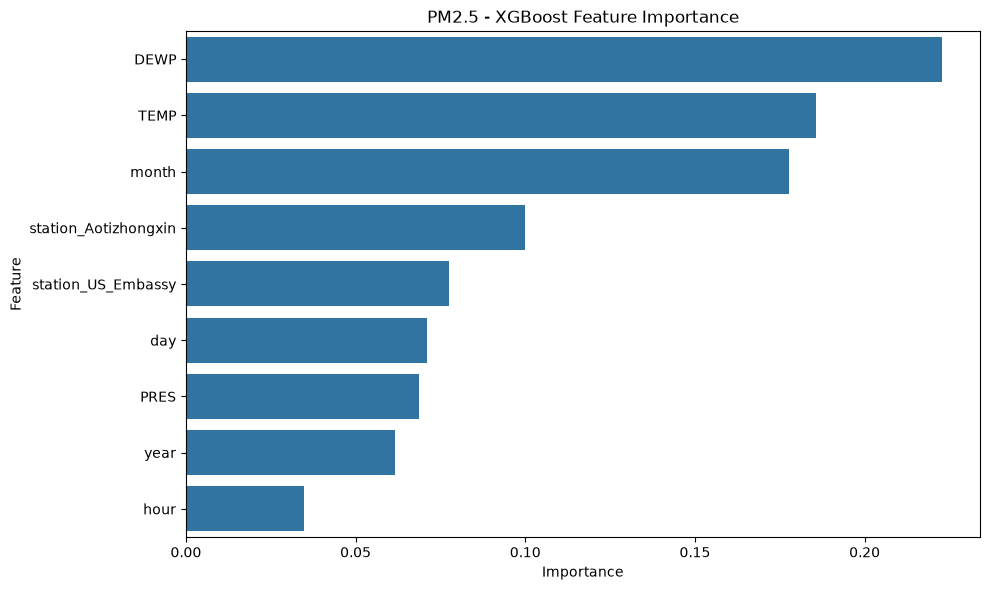

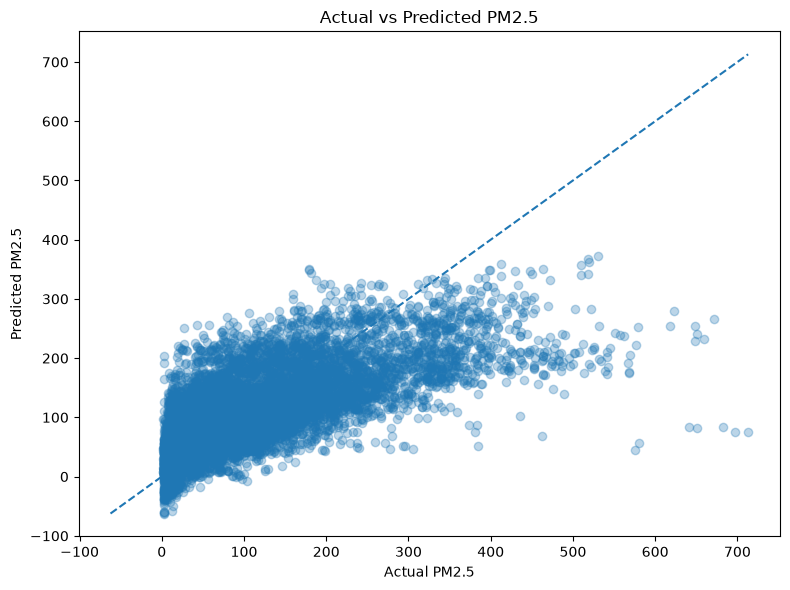

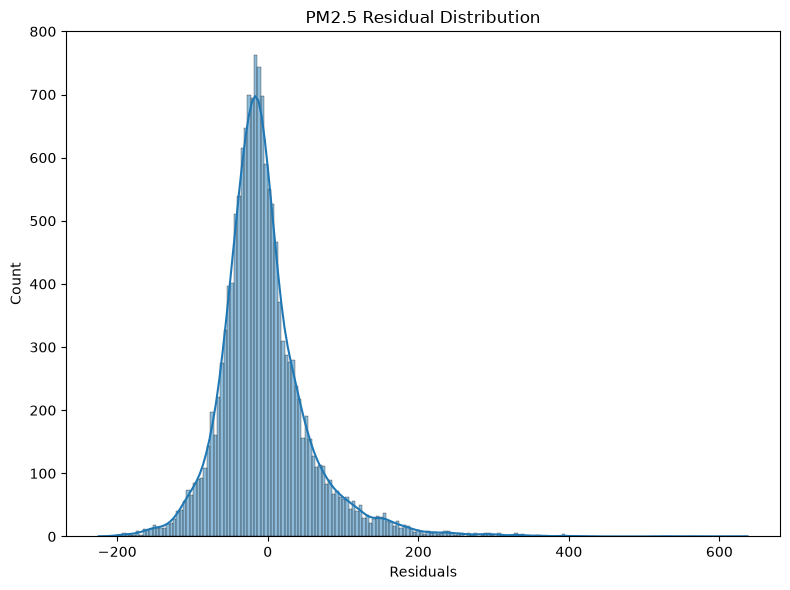


تم الانتهاء من تدريب النموذج بنجاح
Experiment ID: 2
Run ID: 5a527f944d1340d2ad374ac070325c25
Registered Model: PM25_XGBoost_Regression_Predictor

نتائج النموذج:
Train MAE: 36.3947
Test MAE: 42.9502
Test RMSE: 61.6209
Test R2: 0.5348

تم تسجيل النموذج والنتائج والرسومات والملفات داخل MLflow
🏃 View run PM25_XGBoost_Regression at: http://127.0.0.1:5001/#/experiments/2/runs/5a527f944d1340d2ad374ac070325c25
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/2


In [3]:

# ====================================================================
# إعداد المكتبات والاتصال بخادم MLflow
# ====================================================================

import os
import time
import joblib
import mlflow
import mlflow.xgboost
import xgboost as xgb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from datetime import datetime
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from mlflow.models import infer_signature


# ====================================================================
# إعداد مسارات المشروع
# ====================================================================

MODELS_DIR = Path("models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

ARTIFACTS_DIR = Path("mlflow_artifacts")
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

DATASET_PATH = Path("Beijing_PM25_Training_Ready_75896.csv")

ENCODER_PATH = Path("pm25_encoder.pkl")
FEATURE_COLUMNS_PATH = Path("pm25_feature_columns.pkl")


# ====================================================================
# إعداد الاتصال بخادم MLflow
# ====================================================================

mlflow.set_tracking_uri("http://127.0.0.1:5001")

EXPERIMENT_NAME = "PM25_Prediction_Experiments"
REGISTERED_MODEL_NAME = "PM25_XGBoost_Regression_Predictor"

mlflow.set_experiment(EXPERIMENT_NAME)

print("MLflow Tracking URI:", mlflow.get_tracking_uri())
print("Experiment Name:", EXPERIMENT_NAME)
print("Registered Model Name:", REGISTERED_MODEL_NAME)


# ====================================================================
# التحقق من الاتصال بخادم MLflow
# ====================================================================

client = mlflow.tracking.MlflowClient()

experiments = client.search_experiments()

print("\nتم الاتصال بخادم MLflow بنجاح!")
print("عدد التجارب:", len(experiments))


# ====================================================================
# تحميل البيانات وأدوات المعالجة
# ====================================================================

df = pd.read_csv(DATASET_PATH)

encoder = joblib.load(ENCODER_PATH)
feature_columns = joblib.load(FEATURE_COLUMNS_PATH)

print("\nتم تحميل البيانات بنجاح")
print("Dataset Shape:", df.shape)
print("Feature Columns:", feature_columns)


# ====================================================================
# تجهيز البيانات
# ====================================================================

target_column = "PM2.5"

base_features = [
    "year",
    "month",
    "day",
    "hour",
    "DEWP",
    "TEMP",
    "PRES"
]

required_columns = base_features + [target_column, "station"]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(f"الأعمدة التالية غير موجودة: {missing_columns}")

df = df.dropna(subset=required_columns).copy()

# ترتيب البيانات زمنياً داخل كل محطة
df["Date"] = pd.to_datetime(
    df[["year", "month", "day", "hour"]]
)

df = df.sort_values(
    ["station", "Date"]
).reset_index(drop=True)


# ====================================================================
# ترميز اسم المحطة
# ====================================================================

station_encoded = encoder.transform(
    df[["station"]]
)

if hasattr(station_encoded, "toarray"):
    station_encoded = station_encoded.toarray()

station_columns = encoder.get_feature_names_out(["station"])

station_df = pd.DataFrame(
    station_encoded,
    columns=station_columns,
    index=df.index
)

X = pd.concat(
    [
        df[base_features].reset_index(drop=True),
        station_df.reset_index(drop=True)
    ],
    axis=1
)

X = X.reindex(
    columns=feature_columns,
    fill_value=0
)

y = df[target_column].reset_index(drop=True)

print("\nتم تجهيز Features بنجاح")
print("X Shape:", X.shape)
print("y Shape:", y.shape)


# ====================================================================
# تقسيم البيانات زمنياً لكل محطة بنسبة 80% تدريب و20% اختبار
# ====================================================================

train_indices = []
test_indices = []

for station_name in df["station"].unique():

    station_indices = df.index[
        df["station"] == station_name
    ].tolist()

    split_index = int(len(station_indices) * 0.8)

    train_indices.extend(
        station_indices[:split_index]
    )

    test_indices.extend(
        station_indices[split_index:]
    )

X_train = X.loc[train_indices]
X_test = X.loc[test_indices]

y_train = y.loc[train_indices]
y_test = y.loc[test_indices]

print("\nتم تقسيم البيانات بنجاح")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


# ====================================================================
# التحقق من سلامة البيانات
# ====================================================================

if X_train.isnull().sum().sum() > 0:
    raise ValueError("توجد قيم مفقودة في بيانات التدريب")

if X_test.isnull().sum().sum() > 0:
    raise ValueError("توجد قيم مفقودة في بيانات الاختبار")

if not np.isfinite(X_train.to_numpy()).all():
    raise ValueError("توجد قيم غير محدودة في بيانات التدريب")

if not np.isfinite(X_test.to_numpy()).all():
    raise ValueError("توجد قيم غير محدودة في بيانات الاختبار")

print("\nالبيانات سليمة وجاهزة للتدريب")


# ====================================================================
# إعداد معاملات نموذج XGBoost
# ====================================================================

xgb_params = {
    "objective": "reg:squarederror",
    "n_estimators": 500,
    "learning_rate": 0.05,
    "max_depth": 4,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "min_child_weight": 5,
    "reg_alpha": 0.1,
    "reg_lambda": 1,
    "eval_metric": "rmse",
    "random_state": 42,
    "n_jobs": -1
}


# ====================================================================
# بدء تجربة MLflow وتدريب النموذج
# ====================================================================

with mlflow.start_run(
    run_name="PM25_XGBoost_Regression"
) as run:

    print("\nMLflow Run ID:", run.info.run_id)

    # تسجيل وقت بداية التدريب
    training_start = time.time()

    # إنشاء النموذج
    xgb_model = xgb.XGBRegressor(**xgb_params)

    # تدريب النموذج
    xgb_model.fit(
        X_train,
        y_train
    )

    # حساب وقت التدريب
    training_time = time.time() - training_start

    # تسجيل وقت بداية التنبؤ
    prediction_start = time.time()

    # إجراء التنبؤ
    y_pred = xgb_model.predict(X_test)

    # حساب وقت التنبؤ
    prediction_time = time.time() - prediction_start


    # ====================================================================
    # تقييم النموذج
    # ====================================================================

    train_predictions = xgb_model.predict(X_train)

    train_mae = mean_absolute_error(
        y_train,
        train_predictions
    )

    test_mae = mean_absolute_error(
        y_test,
        y_pred
    )

    test_rmse = np.sqrt(
        mean_squared_error(y_test, y_pred)
    )

    test_r2 = r2_score(
        y_test,
        y_pred
    )

    print("\nنتائج تقييم النموذج")
    print("------------------------------")
    print("Train MAE:", train_mae)
    print("Test MAE:", test_mae)
    print("Test RMSE:", test_rmse)
    print("Test R2:", test_r2)
    print("Training Time:", training_time)
    print("Prediction Time:", prediction_time)


    # ====================================================================
    # تسجيل معاملات النموذج في MLflow
    # ====================================================================

    mlflow.log_params(xgb_params)

    mlflow.log_param(
        "dataset",
        DATASET_PATH.name
    )

    mlflow.log_param(
        "number_of_features",
        X_train.shape[1]
    )

    mlflow.log_param(
        "training_samples",
        X_train.shape[0]
    )

    mlflow.log_param(
        "testing_samples",
        X_test.shape[0]
    )

    mlflow.log_param(
        "split_strategy",
        "Chronological 80/20 per station"
    )


    # ====================================================================
    # تسجيل مقاييس الأداء
    # ====================================================================

    mlflow.log_metrics({
        "train_mae": train_mae,
        "test_mae": test_mae,
        "test_rmse": test_rmse,
        "test_r2": test_r2,
        "training_time_seconds": training_time,
        "prediction_time_seconds": prediction_time
    })


    # ====================================================================
    # حفظ النموذج محلياً
    # ====================================================================

    model_path = MODELS_DIR / "best_pm25_model.pkl"

    joblib.dump(
        xgb_model,
        model_path
    )

    model_size_mb = model_path.stat().st_size / (1024 * 1024)

    mlflow.log_metric(
        "model_size_mb",
        model_size_mb
    )

    print("\nModel Size:", round(model_size_mb, 4), "MB")


    # ====================================================================
    # تسجيل النموذج داخل MLflow
    # ====================================================================

    signature = infer_signature(
        X_test,
        y_pred
    )

    input_example = X_test.head(5)

    mlflow.xgboost.log_model(
        xgb_model=xgb_model,
        artifact_path="pm25_xgboost_model",
        signature=signature,
        input_example=input_example,
        registered_model_name=REGISTERED_MODEL_NAME
    )


    # ====================================================================
    # حفظ أدوات المعالجة داخل MLflow
    # ====================================================================

    encoder_artifact_path = ARTIFACTS_DIR / "pm25_encoder.pkl"

    feature_artifact_path = ARTIFACTS_DIR / "pm25_feature_columns.pkl"

    joblib.dump(
        encoder,
        encoder_artifact_path
    )

    joblib.dump(
        feature_columns,
        feature_artifact_path
    )

    mlflow.log_artifact(
        str(encoder_artifact_path),
        artifact_path="preprocessing"
    )

    mlflow.log_artifact(
        str(feature_artifact_path),
        artifact_path="preprocessing"
    )

    mlflow.log_artifact(
        str(DATASET_PATH),
        artifact_path="dataset"
    )


    # ====================================================================
    # رسم وحفظ أهمية الخصائص
    # ====================================================================

    importance = xgb_model.feature_importances_

    importance_df = pd.DataFrame({
        "Feature": X_train.columns,
        "Importance": importance
    })

    importance_df = importance_df.sort_values(
        by="Importance",
        ascending=False
    )

    plt.figure(figsize=(10, 6))

    sns.barplot(
        data=importance_df,
        x="Importance",
        y="Feature"
    )

    plt.title("PM2.5 - XGBoost Feature Importance")
    plt.tight_layout()

    feature_importance_path = ARTIFACTS_DIR / "feature_importance.png"

    plt.savefig(
        feature_importance_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    mlflow.log_artifact(
        str(feature_importance_path),
        artifact_path="plots"
    )


    # ====================================================================
    # رسم القيم الفعلية مقابل القيم المتوقعة
    # ====================================================================

    plt.figure(figsize=(8, 6))

    plt.scatter(
        y_test,
        y_pred,
        alpha=0.3
    )

    min_value = min(y_test.min(), y_pred.min())
    max_value = max(y_test.max(), y_pred.max())

    plt.plot(
        [min_value, max_value],
        [min_value, max_value],
        linestyle="--"
    )

    plt.xlabel("Actual PM2.5")
    plt.ylabel("Predicted PM2.5")
    plt.title("Actual vs Predicted PM2.5")

    plt.tight_layout()

    actual_predicted_path = ARTIFACTS_DIR / "actual_vs_predicted.png"

    plt.savefig(
        actual_predicted_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    mlflow.log_artifact(
        str(actual_predicted_path),
        artifact_path="plots"
    )


    # ====================================================================
    # تحليل الأخطاء Residual Analysis
    # ====================================================================

    residuals = y_test.to_numpy() - y_pred

    plt.figure(figsize=(8, 6))

    sns.histplot(
        residuals,
        kde=True
    )

    plt.xlabel("Residuals")
    plt.title("PM2.5 Residual Distribution")

    plt.tight_layout()

    residual_path = ARTIFACTS_DIR / "residual_distribution.png"

    plt.savefig(
        residual_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    mlflow.log_artifact(
        str(residual_path),
        artifact_path="plots"
    )


    # ====================================================================
    # تسجيل تقرير الأداء كملف نصي
    # ====================================================================

    report_path = ARTIFACTS_DIR / "model_report.txt"

    with open(
        report_path,
        "w",
        encoding="utf-8"
    ) as report_file:

        report_file.write("PM2.5 XGBoost Regression Report\n")
        report_file.write("================================\n")

        report_file.write(f"Train MAE: {train_mae:.4f}\n")
        report_file.write(f"Test MAE: {test_mae:.4f}\n")
        report_file.write(f"Test RMSE: {test_rmse:.4f}\n")
        report_file.write(f"Test R2: {test_r2:.4f}\n")

        report_file.write(
            f"Training Time: {training_time:.4f} seconds\n"
        )

        report_file.write(
            f"Prediction Time: {prediction_time:.4f} seconds\n"
        )

        report_file.write(
            f"Model Size: {model_size_mb:.4f} MB\n"
        )

    mlflow.log_artifact(
        str(report_path),
        artifact_path="reports"
    )


    # ====================================================================
    # تسجيل أهمية الخصائص كملف CSV
    # ====================================================================

    importance_csv_path = ARTIFACTS_DIR / "feature_importance.csv"

    importance_df.to_csv(
        importance_csv_path,
        index=False
    )

    mlflow.log_artifact(
        str(importance_csv_path),
        artifact_path="reports"
    )


    # ====================================================================
    # عرض نتيجة التجربة
    # ====================================================================

    print("\n========================================")
    print("تم الانتهاء من تدريب النموذج بنجاح")
    print("========================================")

    print("Experiment ID:", run.info.experiment_id)
    print("Run ID:", run.info.run_id)
    print("Registered Model:", REGISTERED_MODEL_NAME)

    print("\nنتائج النموذج:")
    print("Train MAE:", round(train_mae, 4))
    print("Test MAE:", round(test_mae, 4))
    print("Test RMSE:", round(test_rmse, 4))
    print("Test R2:", round(test_r2, 4))

    print("\nتم تسجيل النموذج والنتائج والرسومات والملفات داخل MLflow")
